In [1]:
# 0. Setup and load the Iris dataset
# If needed, install packages in a notebook cell with:
# %pip install pandas numpy matplotlib seaborn scikit-learn scipy

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.cluster import KMeans
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, silhouette_score
)
from sklearn.metrics import pairwise_distances
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

DATA_PATH = "iris.csv"
if not os.path.exists(DATA_PATH) and os.path.exists("/mnt/data/iris.csv"):
    DATA_PATH = "/mnt/data/iris.csv"

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())
print("\nColumn names:", df.columns.tolist())
print("\nMissing values per column:")
print(df.isnull().sum())

# This notebook expects four numeric measurement columns and one species/label column.
feature_cols = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
target_col = "species"

# If your column names differ, edit feature_cols and target_col above.
X = df[feature_cols].copy()
y = df[target_col].astype(str).copy()

print("\nSpecies counts:")
print(y.value_counts())


Dataset shape: (150, 5)

First 5 rows:


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



Column names: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

Missing values per column:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Species counts:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


Iterations completed: 3
Cluster counts:
Cluster
0    44
1    50
2    56
Name: count, dtype: int64
Medoid row indices (0-based): [ 94   7 147]

Medoid flowers:


,sepal_length,sepal_width,petal_length,petal_width,species
94,5.6,2.7,4.2,1.3,versicolor
7,5.0,3.4,1.5,0.2,setosa
147,6.5,3.0,5.2,2.0,virginica


Silhouette score: 0.4497


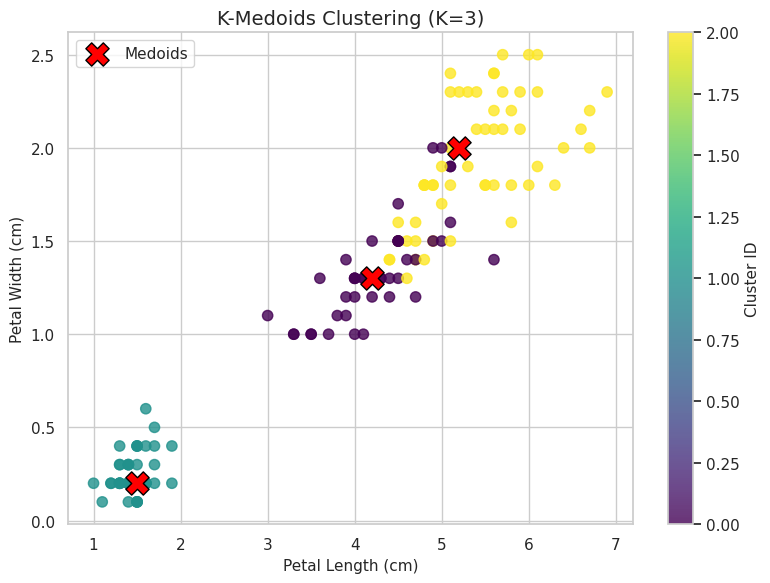

,sepal_length,sepal_width,petal_length,petal_width,species,Cluster
0,5.1,3.5,1.4,0.2,setosa,1
1,4.9,3.0,1.4,0.2,setosa,1
2,4.7,3.2,1.3,0.2,setosa,1
3,4.6,3.1,1.5,0.2,setosa,1
4,5.0,3.6,1.4,0.2,setosa,1
5,5.4,3.9,1.7,0.4,setosa,1
6,4.6,3.4,1.4,0.3,setosa,1
7,5.0,3.4,1.5,0.2,setosa,1
8,4.4,2.9,1.4,0.2,setosa,1
9,4.9,3.1,1.5,0.1,setosa,1


In [9]:
# 9. K-Medoids (simple alternate-update implementation)
X_scaled_med = StandardScaler().fit_transform(df[feature_cols])
D = pairwise_distances(X_scaled_med, metric="euclidean")
n_samples = len(df)
k = 3

rng = np.random.default_rng(42)
medoids = rng.choice(n_samples, size=k, replace=False)

for iteration in range(100):
    assignments = np.argmin(D[:, medoids], axis=1)
    new_medoids = medoids.copy()

    for cluster_id in range(k):
        members = np.where(assignments == cluster_id)[0]
        if len(members) == 0:
            # Reinitialize an empty cluster to a sample not already used as a medoid.
            candidates = np.setdiff1d(np.arange(n_samples), new_medoids)
            if len(candidates):
                new_medoids[cluster_id] = rng.choice(candidates)
            continue

        within_distances = D[np.ix_(members, members)]
        total_distance = within_distances.sum(axis=1)
        new_medoids[cluster_id] = members[np.argmin(total_distance)]

    if np.array_equal(medoids, new_medoids):
        break
    medoids = new_medoids

assignments = np.argmin(D[:, medoids], axis=1)
df_med = df.copy()
df_med["Cluster"] = assignments

print("Iterations completed:", iteration + 1)
print("Cluster counts:")
print(df_med["Cluster"].value_counts().sort_index())
print("Medoid row indices (0-based):", medoids)
print("\nMedoid flowers:")
display(df.iloc[medoids][feature_cols + ["species"]])

if len(np.unique(assignments)) > 1:
    print(f"Silhouette score: {silhouette_score(X_scaled_med, assignments):.4f}")

plt.figure(figsize=(8, 6))
sc = plt.scatter(df_med["petal_length"], df_med["petal_width"],
                 c=assignments, cmap="viridis", s=55, alpha=0.8)
medoid_rows = df.iloc[medoids]
plt.scatter(medoid_rows["petal_length"], medoid_rows["petal_width"],
            marker="X", s=280, c="red", edgecolor="black", label="Medoids")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("K-Medoids Clustering (K=3)")
plt.legend()
plt.colorbar(sc, label="Cluster ID")
plt.tight_layout()
plt.show()

display(df_med[feature_cols + ["species", "Cluster"]].head(10))
